# Group 12 — PLSA Information Retrieval Project (Six-Category Experiment)

This notebook is a **controlled follow-up experiment** to the all-20-category version. It trains PLSA, TF-IDF/VSM, and LSI on a subset of six semantically distinct 20 Newsgroups categories:

- `comp.graphics` — computer graphics
- `misc.forsale` — classifieds / items for sale
- `rec.sport.baseball` — baseball
- `sci.med` — medicine and health
- `sci.space` — space and astronomy
- `talk.politics.guns` — gun politics

The purpose is to test whether retrieval and topic interpretability improve when the corpus has fewer, more distinct categories. **This is a six-category subset, not a relabelling of all 20 categories into six supercategories.** Simply merging labels while retaining every document would change the evaluation labels but would not change the unsupervised PLSA training data.

PLSA itself does not receive category labels during training. Labels are used only for stratified splitting, selecting source documents for the controlled mixture experiment, and evaluating retrieval.

The notebook retains the NumPy/EM PLSA implementation, multiple restarts, topic inspection, controlled baseball/politics mixture experiment, TF-IDF/VSM and LSI comparisons, model-order study, and the explicitly labelled simplified beta experiment. Run all cells from top to bottom to regenerate results.

## 0. Install dependencies

Run once in a notebook environment if required. In Colab, use the first line in a code cell.

In [1]:
# %pip -q install numpy scipy scikit-learn pandas matplotlib

## 1. Imports and reproducibility

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)


## 2. Load a six-category subset of 20 Newsgroups

We deliberately restrict the corpus to six reasonably distinct categories. This changes the documents used to train PLSA, unlike merely merging the original labels after training. The categories remain the dataset's original labels; no labels are passed to PLSA's EM algorithm.

In [3]:
SELECTED_CATEGORIES = [
    "comp.graphics",
    "misc.forsale",
    "rec.sport.baseball",
    "sci.med",
    "sci.space",
    "talk.politics.guns",
]

dataset = fetch_20newsgroups(
    subset="all",
    categories=SELECTED_CATEGORIES,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=SEED
)
documents = np.array(dataset.data, dtype=object)
labels = np.asarray(dataset.target)
target_names = list(dataset.target_names)

print("Selected categories:", len(target_names))
print("Total documents:", len(documents))
for i, name in enumerate(target_names):
    print(f"{i:2d} | {name:25s} | {(labels == i).sum():5d} documents")

print("\nNote: category names are evaluation labels only; PLSA is trained without using them.")

Selected categories: 6
Total documents: 5829
 0 | comp.graphics             |   973 documents
 1 | misc.forsale              |   975 documents
 2 | rec.sport.baseball        |   994 documents
 3 | sci.med                   |   990 documents
 4 | sci.space                 |   987 documents
 5 | talk.politics.guns        |   910 documents

Note: category names are evaluation labels only; PLSA is trained without using them.


### Why use a subset?

The original corpus contains several closely related categories, such as multiple computer groups and multiple religion groups. Here we retain six categories with more distinct subject matter to test whether a smaller, more separable corpus yields more interpretable PLSA topics and better category-query retrieval.

This is a diagnostic experiment, not proof that six topics is the theoretically correct number. We will still vary the latent topic count `K`; the number of dataset categories and the number of latent PLSA topics are different quantities.

## 3. Train/test split and preprocessing

Split the raw documents first. Fit the vocabulary only on the training split to avoid vocabulary leakage from the test documents.

In [5]:

import re
import spacy
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer




docs_train, docs_test, y_train, y_test = train_test_split(
    documents,
    labels,
    test_size=0.25,
    random_state=SEED,
    stratify=labels
)






nlp = spacy.load(
    "en_core_web_sm",
    disable=["ner", "parser"]
)




def preprocess_texts(texts):
    """
    Lowercase, tokenize, remove stop words and punctuation,
    and lemmatize the remaining tokens.

    Returns a list of preprocessed document strings.
    """
    processed_docs = []

    for doc in nlp.pipe(texts, batch_size=256):
        tokens = []

        for token in doc:

            if (
                token.is_space
                or token.is_punct
                or token.like_num
                or not token.is_alpha
            ):
                continue


            if token.is_stop:
                continue


            lemma = token.lemma_.lower().strip()


            if len(lemma) < 2:
                continue

            tokens.append(lemma)

        processed_docs.append(" ".join(tokens))

    return processed_docs



docs_train_processed = preprocess_texts(docs_train)
docs_test_processed = preprocess_texts(docs_test)






count_vectorizer = CountVectorizer(
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,
    max_features=3000,
    min_df=3,
    max_df=0.90,
    dtype=np.float64
)


X_train = count_vectorizer.fit_transform(
    docs_train_processed
)


X_test = count_vectorizer.transform(
    docs_test_processed
)

vocabulary = count_vectorizer.get_feature_names_out()




print("X_train:", X_train.shape, "(documents, vocabulary)")
print("X_test: ", X_test.shape)
print("Example vocabulary:", vocabulary[:20])

print(
    "Empty training documents after preprocessing:",
    sum(not doc.strip() for doc in docs_train_processed)
)

print(
    "Empty test documents after preprocessing:",
    sum(not doc.strip() for doc in docs_test_processed)
)


X_train: (4371, 3000) (documents, vocabulary)
X_test:  (1458, 3000)
Example vocabulary: ['aaa' 'ab' 'abide' 'ability' 'able' 'absolute' 'absolutely' 'abstract'
 'abuse' 'ac' 'academic' 'acceleration' 'accept' 'acceptable' 'access'
 'accident' 'accidental' 'accompany' 'accomplish' 'accord']
Empty training documents after preprocessing: 126
Empty test documents after preprocessing: 46


## 4. PLSA theory

For document \(d\), word \(w\), and latent topic \(z\):

\[
P(w\mid d)=\sum_{z=1}^{K}P(w\mid z)P(z\mid d)
\]

- \(\theta_{d,z}=P(z\mid d)\): document-topic distribution.
- \(\phi_{z,w}=P(w\mid z)\): topic-word distribution.
- Each row of \(\theta\) and \(\phi\) sums to one.

For every observed document-word pair, the E-step computes the posterior responsibility:

\[
P(z\mid d,w)=\frac{P(z\mid d)P(w\mid z)}
{\sum_{z'}P(z'\mid d)P(w\mid z')}
\]

The M-step uses the expected word counts to update both distributions. The process repeats until the log-likelihood stops improving.

In [6]:
class PLSA:
    """PLSA trained directly with NumPy EM and sparse input counts."""

    def __init__(self, n_topics=5, max_iter=100, tol=1e-4,
                 random_state=42, beta=1.0):
        if n_topics < 1:
            raise ValueError("n_topics must be positive")
        if not (0 < beta):
            raise ValueError("beta must be positive")
        self.n_topics = n_topics
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.beta = beta
        self.log_likelihoods = []

    @staticmethod
    def _normalize(a, axis):
        denom = np.maximum(a.sum(axis=axis, keepdims=True), 1e-15)
        return a / denom

    @staticmethod
    def _observations(X):
        X = csr_matrix(X, dtype=np.float64)
        X.eliminate_zeros()
        X.sum_duplicates()
        docs, words, counts = [], [], []
        for d in range(X.shape[0]):
            start, end = X.indptr[d], X.indptr[d + 1]
            if end > start:
                docs.append(np.full(end-start, d, dtype=np.int64))
                words.append(X.indices[start:end].astype(np.int64))
                counts.append(X.data[start:end].astype(np.float64))
        if not docs:
            raise ValueError("Input has no observed word counts.")
        return X, np.concatenate(docs), np.concatenate(words), np.concatenate(counts)

    def fit(self, X):
        X, doc_ids, word_ids, counts = self._observations(X)
        D, V = X.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state)

        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)
        phi = self._normalize(rng.random((K, V)) + 1e-3, axis=1)
        self.log_likelihoods = []

        for iteration in range(self.max_iter):

            unnorm = theta[doc_ids].T * phi[:, word_ids]
            if self.beta != 1.0:
                unnorm = np.maximum(unnorm, 1e-15) ** self.beta
            posterior = unnorm / np.maximum(
                unnorm.sum(axis=0, keepdims=True), 1e-15
            )


            weighted = posterior * counts[None, :]
            topic_word = np.zeros((K, V), dtype=np.float64)
            doc_topic = np.zeros((D, K), dtype=np.float64)

            for k in range(K):
                np.add.at(topic_word[k], word_ids, weighted[k])
                np.add.at(doc_topic[:, k], doc_ids, weighted[k])

            phi = self._normalize(topic_word + 1e-12, axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)


            p_observed = np.sum(theta[doc_ids] * phi[:, word_ids].T, axis=1)
            ll = float(np.sum(counts * np.log(np.maximum(p_observed, 1e-15))))
            self.log_likelihoods.append(ll)

            if iteration > 0:
                improvement = ll - previous_ll
                if self.beta == 1.0 and improvement < -1e-7:
                    print("Warning: likelihood decreased slightly; check numerical behavior.")
                if abs(improvement) <= self.tol * (1 + abs(previous_ll)):
                    break
            previous_ll = ll

        self.theta_ = theta
        self.phi_ = phi
        self.n_features_in_ = V
        self.n_iter_ = len(self.log_likelihoods)
        return self

    def transform(self):
        """Document-topic probabilities for the documents used in fit()."""
        return self.theta_

    def fold_in(self, X_new, max_iter=100):
        """Infer P(z|d_new) with learned P(w|z) fixed."""
        X_new = csr_matrix(X_new, dtype=np.float64)
        if X_new.shape[1] != self.n_features_in_:
            raise ValueError("New data must use the same fitted vocabulary.")
        D, V = X_new.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state + 1000)
        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)

        for _ in range(max_iter):
            doc_topic = np.zeros((D, K), dtype=np.float64)
            for d in range(D):
                start, end = X_new.indptr[d], X_new.indptr[d + 1]
                words = X_new.indices[start:end]
                counts = X_new.data[start:end]
                if len(words) == 0:
                    continue
                unnorm = theta[d, :, None] * self.phi_[:, words]
                if self.beta != 1.0:
                    unnorm = np.maximum(unnorm, 1e-15) ** self.beta
                posterior = unnorm / np.maximum(
                    unnorm.sum(axis=0, keepdims=True), 1e-15
                )
                doc_topic[d] = (posterior * counts[None, :]).sum(axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)
        return theta

    def top_words(self, vocabulary, n=10):
        result = {}
        for k, dist in enumerate(self.phi_):
            ids = np.argsort(dist)[::-1][:n]
            result[k] = [(vocabulary[i], float(dist[i])) for i in ids]
        return result


## 5. Multiple random restarts

EM can settle at different local optima. Fit several initializations and select the model with the largest training log-likelihood. This selection criterion is only about training fit; final retrieval quality must still be evaluated on held-out documents.

The six dataset categories do **not** force us to use `K=6`: latent topics may merge categories or split a category. We start with `K=6` as a reasonable comparison point, then inspect other values in the model-order study.

In [7]:
def train_plsa_restarts(X, n_topics=5, n_restarts=5,
                        max_iter=100, tol=1e-4, base_seed=42):
    runs = []
    for r in range(n_restarts):
        model = PLSA(
            n_topics=n_topics, max_iter=max_iter, tol=tol,
            random_state=base_seed + r, beta=1.0
        ).fit(X)
        final_ll = model.log_likelihoods[-1]
        runs.append((model, final_ll))
        print(f"Restart {r+1}: final training log-likelihood={final_ll:.3f}, "
              f"iterations={model.n_iter_}")
    best_model, best_ll = max(runs, key=lambda item: item[1])
    print("Selected best training likelihood:", round(best_ll, 3))
    return best_model, runs

K = 6
best_plsa, restart_runs = train_plsa_restarts(
    X_train, n_topics=K, n_restarts=5, max_iter=100
)
theta_train = best_plsa.transform()
theta_test = best_plsa.fold_in(X_test, max_iter=100)
print("theta_train:", theta_train.shape)
print("theta_test:", theta_test.shape)


Restart 1: final training log-likelihood=-1765727.747, iterations=48
Restart 2: final training log-likelihood=-1772675.710, iterations=48
Restart 3: final training log-likelihood=-1768344.564, iterations=47
Restart 4: final training log-likelihood=-1776751.017, iterations=43
Restart 5: final training log-likelihood=-1775407.303, iterations=42
Selected best training likelihood: -1765727.747
theta_train: (4371, 6)
theta_test: (1458, 6)


## 6. Inspect topics and convergence

Topic IDs are arbitrary: topic 0 is not inherently sports or politics. Interpret each topic by its highest-probability words, and use category-level averages only as a diagnostic.


Topic 0:
game (0.023), year (0.019), run (0.012), team (0.012), good (0.012), player (0.010), hit (0.010), win (0.010), play (0.009), think (0.008), time (0.008), get (0.007)

Topic 1:
patient (0.010), medical (0.009), study (0.009), disease (0.008), cancer (0.007), doctor (0.007), cause (0.007), drug (0.007), effect (0.006), health (0.006), food (0.006), treatment (0.006)

Topic 2:
people (0.013), think (0.013), gun (0.012), know (0.010), like (0.009), right (0.008), thing (0.007), time (0.007), go (0.006), say (0.006), want (0.006), good (0.006)

Topic 3:
space (0.022), launch (0.011), nasa (0.007), earth (0.007), orbit (0.007), satellite (0.007), mission (0.007), system (0.007), year (0.006), moon (0.006), shuttle (0.006), cost (0.005)

Topic 4:
new (0.016), include (0.012), sale (0.012), price (0.011), offer (0.011), sell (0.010), mail (0.009), drive (0.009), copy (0.008), card (0.008), good (0.008), ask (0.007)

Topic 5:
image (0.025), file (0.016), program (0.011), jpeg (0.011),

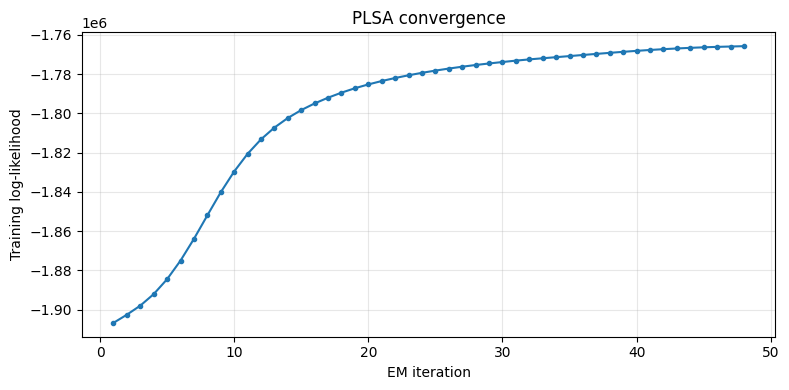

In [8]:
for topic_id, words in best_plsa.top_words(vocabulary, n=12).items():
    print(f"\nTopic {topic_id}:")
    print(", ".join(f"{word} ({prob:.3f})" for word, prob in words))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(best_plsa.log_likelihoods)+1),
         best_plsa.log_likelihoods, marker="o", markersize=3)
plt.xlabel("EM iteration")
plt.ylabel("Training log-likelihood")
plt.title("PLSA convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Controlled topic-boundary experiment

Generate artificial documents by sampling word tokens from source documents in two of the selected categories: baseball and gun politics. Infer their topic mixtures with folding-in and compare the known source proportions with the estimated probabilities.

**Interpretation caution:** a source-word ratio is not guaranteed to equal a latent-topic probability. Topics can split a category or overlap categories. We identify the baseball-associated and politics-associated topics from the average training-document topic distributions for those source categories.

In [9]:
sports_class = target_names.index("rec.sport.baseball")
politics_class = target_names.index("talk.politics.guns")

class_topic_means = np.vstack([
    theta_train[y_train == c].mean(axis=0)
    for c in range(len(target_names))
])
sports_topic = int(class_topic_means[sports_class].argmax())
politics_topic = int(class_topic_means[politics_class].argmax())

print("Sports-associated topic:", sports_topic)
print("Politics-associated topic:", politics_topic)
if sports_topic == politics_topic:
    print("Warning: both categories map to the same dominant topic; interpret estimates cautiously.")

def sample_token_ids(row):
    row = csr_matrix(row)
    return np.repeat(row.indices, row.data.astype(int))

def make_mixed_document(X_source, y_source, class_a, class_b,
                        ratio_a, rng, n_tokens=300):

    a_candidates = np.where((y_source == class_a) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]
    b_candidates = np.where((y_source == class_b) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]

    da = X_source[a_candidates[rng.integers(len(a_candidates))]]
    db = X_source[b_candidates[rng.integers(len(b_candidates))]]
    tokens_a = sample_token_ids(da)
    tokens_b = sample_token_ids(db)
    if len(tokens_a) == 0 or len(tokens_b) == 0:
        raise ValueError("A sampled source document had no in-vocabulary tokens.")
    n_a = int(round(n_tokens * ratio_a))
    n_b = n_tokens - n_a
    tokens = np.concatenate([
        rng.choice(tokens_a, size=n_a, replace=True),
        rng.choice(tokens_b, size=n_b, replace=True)
    ])
    counts = np.bincount(tokens, minlength=X_source.shape[1]).astype(float)
    return csr_matrix(counts.reshape(1, -1))

boundary_rng = np.random.default_rng(SEED + 77)
ratios = [0.9, 0.7, 0.5, 0.3, 0.1]
boundary_rows = []

for ratio in ratios:
    for replicate in range(20):
        mixed_X = make_mixed_document(
            X_train, y_train, sports_class, politics_class,
            ratio, boundary_rng, n_tokens=300
        )
        estimate = best_plsa.fold_in(mixed_X, max_iter=100)[0]
        boundary_rows.append({
            "source_category_a": "rec.sport.baseball",
            "source_category_b": "talk.politics.guns",
            "actual_sports_word_ratio": ratio,
            "actual_politics_word_ratio": 1-ratio,
            "estimated_sports_topic": estimate[sports_topic],
            "estimated_politics_topic": estimate[politics_topic],
            "replicate": replicate
        })

boundary_df = pd.DataFrame(boundary_rows)
boundary_summary = boundary_df.groupby("actual_sports_word_ratio").agg(
    estimated_sports_mean=("estimated_sports_topic", "mean"),
    estimated_sports_std=("estimated_sports_topic", "std"),
    estimated_politics_mean=("estimated_politics_topic", "mean"),
    estimated_politics_std=("estimated_politics_topic", "std")
).reset_index()
display(boundary_summary)

Sports-associated topic: 0
Politics-associated topic: 2


,actual_sports_word_ratio,estimated_sports_mean,estimated_sports_std,estimated_politics_mean,estimated_politics_std
0,0.1,0.105389,0.100130,0.790580,0.142756
1,0.3,0.221837,0.119755,0.675847,0.130770
2,0.5,0.426018,0.141819,0.483582,0.116764
3,0.7,0.521658,0.177170,0.404722,0.160217
4,0.9,0.662207,0.268226,0.254446,0.214282


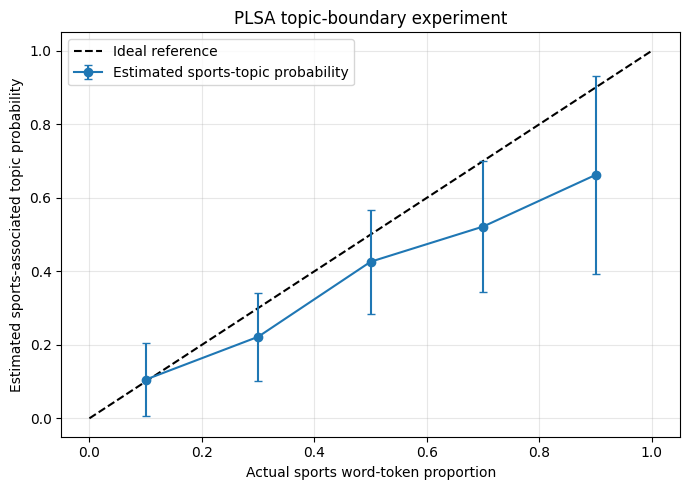

In [10]:
plt.figure(figsize=(7, 5))
plt.plot([0, 1], [0, 1], "k--", label="Ideal reference")
plt.errorbar(
    boundary_summary["actual_sports_word_ratio"],
    boundary_summary["estimated_sports_mean"],
    yerr=boundary_summary["estimated_sports_std"],
    marker="o", capsize=3, label="Estimated sports-topic probability"
)
plt.xlabel("Actual sports word-token proportion")
plt.ylabel("Estimated sports-associated topic probability")
plt.title("PLSA topic-boundary experiment")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 8. TF-IDF/VSM and LSI baselines

All baselines are fitted on training documents only. LSI uses truncated SVD on TF-IDF representations; it is a geometric low-rank representation, unlike PLSA's normalized probability distributions.

In [11]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,
    max_features=3000,
    min_df=3,
    max_df=0.90
)

X_train_tfidf = tfidf_vectorizer.fit_transform(docs_train_processed)
X_test_tfidf = tfidf_vectorizer.transform(docs_test_processed)

n_components = min(50, X_train_tfidf.shape[0]-1, X_train_tfidf.shape[1]-1)
lsi_model = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    Normalizer(copy=False)
)
lsi_train = lsi_model.fit_transform(X_train_tfidf)
lsi_test = lsi_model.transform(X_test_tfidf)

print("TF-IDF train/test:", X_train_tfidf.shape, X_test_tfidf.shape)
print("LSI train/test:", lsi_train.shape, lsi_test.shape)


TF-IDF train/test: (4371, 3000) (1458, 3000)
LSI train/test: (4371, 50) (1458, 50)


## 9. Retrieval metrics and fair comparison

For each query, relevance is defined using the known held-out category labels. The same test collection and relevance class are used for PLSA, LSI, and TF-IDF. This is a small demonstration with one query per category; category labels are a proxy for relevance, not human relevance judgments. PLSA is evaluated using both cosine similarity in document-topic space and probabilistic query likelihood derived from P(w|d)=sum_z P(w|z)P(z|d).

In [12]:
category_queries = {
    "comp.graphics": "computer graphics rendering image pixels",
    "misc.forsale": "for sale price shipping offer",
    "rec.sport.baseball": "baseball players team season game",
    "sci.med": "medical doctor disease treatment health",
    "sci.space": "space NASA spacecraft orbit planet",
    "talk.politics.guns": "gun control firearms second amendment",
}

missing = sorted(set(target_names) - set(category_queries))
extra = sorted(set(category_queries) - set(target_names))
print("Categories without a query:", missing)
print("Query names not found in dataset:", extra)



nonempty_test_mask = np.asarray([bool(doc.strip()) for doc in docs_test_processed])
print("Non-empty test documents:", int(nonempty_test_mask.sum()), "/", len(docs_test_processed))

def plsa_query_log_likelihood(query_counts, document_theta, phi, smoothing=1e-10):
    """
    Rank documents by log P(query | document) under PLSA:
        P(w | d) = sum_z P(w | z) P(z | d)
    Query term counts are used as multiplicities. A small floor prevents log(0).
    Returns one score per document; higher is better.
    """
    query_counts = csr_matrix(query_counts, dtype=np.float64)
    scores = np.zeros(document_theta.shape[0], dtype=np.float64)
    for word_id, count in zip(query_counts.indices, query_counts.data):
        p_word_given_doc = document_theta @ phi[:, word_id]
        scores += count * np.log(np.maximum(p_word_given_doc, smoothing))
    return scores


def evaluate_query(query_text, target_label, k=10):
    processed_query = preprocess_texts([query_text])[0]
    if not processed_query.strip():
        print(f"Warning: query for {target_names[target_label]} became empty after preprocessing.")

    q_tfidf = tfidf_vectorizer.transform([processed_query])
    q_lsi = lsi_model.transform(q_tfidf)
    q_counts = count_vectorizer.transform([processed_query]).astype(np.float64)
    q_plsa = best_plsa.fold_in(q_counts, max_iter=100)

    sim_tfidf = cosine_similarity(q_tfidf, X_test_tfidf).ravel()[nonempty_test_mask]
    sim_lsi = cosine_similarity(q_lsi, lsi_test).ravel()[nonempty_test_mask]
    sim_plsa_cosine = cosine_similarity(q_plsa, theta_test).ravel()[nonempty_test_mask]
    sim_plsa_likelihood = plsa_query_log_likelihood(
        q_counts, theta_test, best_plsa.phi_
    )[nonempty_test_mask]
    y_eval = y_test[nonempty_test_mask]

    methods = {
        "TF-IDF/VSM": sim_tfidf,
        "LSI": sim_lsi,
        "PLSA cosine": sim_plsa_cosine,
        "PLSA query likelihood": sim_plsa_likelihood,
    }
    rows = []
    total_relevant = int((y_eval == target_label).sum())
    if total_relevant == 0:
        return rows

    for method_name, similarities in methods.items():
        top_indices = np.argsort(similarities)[::-1][:k]
        true_positives = int((y_eval[top_indices] == target_label).sum())
        precision = true_positives / min(k, len(y_eval))
        recall = true_positives / total_relevant
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        rows.append({
            "query_category": target_names[target_label],
            "query_text": query_text,
            "method": method_name,
            "Precision@k": precision,
            "Recall@k": recall,
            "F1@k": f1,
            "relevant_test_documents": total_relevant,
            "k": k,
        })
    return rows

eval_rows = []
for category_name in target_names:
    eval_rows.extend(evaluate_query(category_queries[category_name], target_names.index(category_name), k=10))

evaluation_df = pd.DataFrame(eval_rows)
display(evaluation_df)
print("\nMean metrics across the six category queries:")
display(evaluation_df.groupby("method")[["Precision@k", "Recall@k", "F1@k"]].mean())


Categories without a query: []
Query names not found in dataset: []
Non-empty test documents: 1412 / 1458


,query_category,query_text,method,Precision@k,Recall@k,F1@k,relevant_test_documents,k
0,comp.graphics,computer graphics rendering image pixels,TF-IDF/VSM,0.9,0.037975,0.072874,237,10
1,comp.graphics,computer graphics rendering image pixels,LSI,0.9,0.037975,0.072874,237,10
2,comp.graphics,computer graphics rendering image pixels,PLSA cosine,1.0,0.042194,0.080972,237,10
3,comp.graphics,computer graphics rendering image pixels,PLSA query likelihood,1.0,0.042194,0.080972,237,10
4,misc.forsale,for sale price shipping offer,TF-IDF/VSM,1.0,0.042017,0.080645,238,10
5,misc.forsale,for sale price shipping offer,LSI,1.0,0.042017,0.080645,238,10
6,misc.forsale,for sale price shipping offer,PLSA cosine,0.7,0.029412,0.056452,238,10
7,misc.forsale,for sale price shipping offer,PLSA query likelihood,1.0,0.042017,0.080645,238,10
8,rec.sport.baseball,baseball players team season game,TF-IDF/VSM,1.0,0.041667,0.080000,240,10
9,rec.sport.baseball,baseball players team season game,LSI,1.0,0.041667,0.080000,240,10



Mean metrics across the six category queries:


,Precision@k,Recall@k,F1@k
method,,,
LSI,0.983333,0.041824,0.080232
PLSA cosine,0.833333,0.035374,0.067865
PLSA query likelihood,0.966667,0.041126,0.078893
TF-IDF/VSM,0.983333,0.041824,0.080232


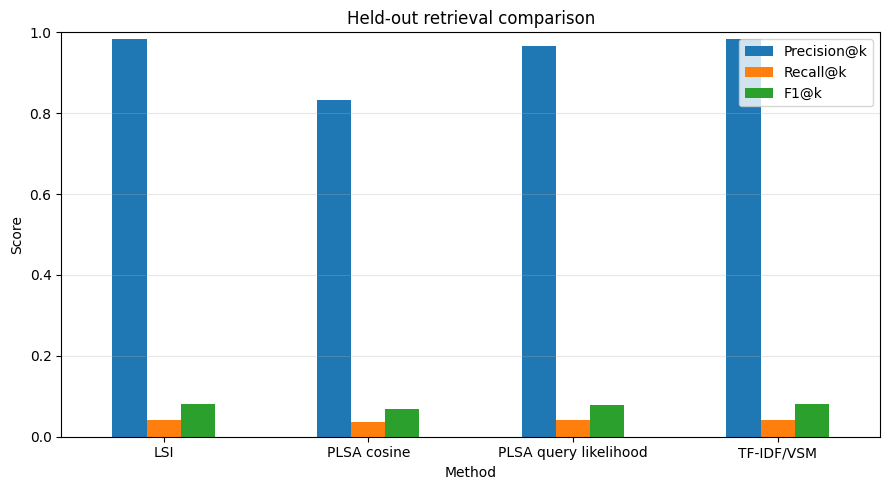

In [13]:
mean_metrics = evaluation_df.groupby("method")[["Precision@k", "Recall@k", "F1@k"]].mean()
mean_metrics.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
plt.title("Held-out retrieval comparison")
plt.ylabel("Score")
plt.xlabel("Method")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Model-order study: how does K affect the model?

The proposal asks us to study how the number of latent topics affects convergence and topic separation. Compare several values of `K` on the same six-category training set. This version records training likelihood and convergence iterations; it does not claim training likelihood alone measures generalization or retrieval quality.

In [14]:
k_rows = []
for k_topics in [2, 3, 5, 6, 8, 10]:
    model = PLSA(
        n_topics=k_topics, max_iter=80, tol=1e-4,
        random_state=SEED, beta=1.0
    ).fit(X_train)
    k_rows.append({
        "K": k_topics,
        "iterations": model.n_iter_,
        "train_log_likelihood": model.log_likelihoods[-1],
        "test_documents": X_test.shape[0]
    })

k_df = pd.DataFrame(k_rows)
display(k_df)


,K,iterations,train_log_likelihood,test_documents
0,2,21,-1.855303e+06,1458
1,3,63,-1.832125e+06,1458
2,5,53,-1.783497e+06,1458
3,6,48,-1.765728e+06,1458
4,8,79,-1.743961e+06,1458
5,10,58,-1.731637e+06,1458


## 11. Optional extension: tempered E-step (exploratory)

Hofmann's paper introduces Tempered EM as an entropy-regularized fitting procedure and recommends evaluating held-out performance while changing the inverse temperature. The `beta` option in the class is a simplified tempered E-step, **not a full reproduction of the paper's TEM schedule**. Treat this section as exploratory only, and don't claim that it fully implements TEM.

For a proper TEM experiment, start with standard EM at beta=1, lower beta in small steps, run tempered iterations, and monitor held-out predictive likelihood/perplexity; stop when held-out performance deteriorates. A rigorous implementation should define and document the exact schedule and stopping rule.

In [15]:
tempered_rows = []
for beta in [1.0, 0.9, 0.8, 0.7]:
    model = PLSA(
        n_topics=K, max_iter=80, tol=1e-4,
        random_state=SEED, beta=beta
    ).fit(X_train)
    tempered_rows.append({
        "beta": beta,
        "iterations": model.n_iter_,
        "train_log_likelihood": model.log_likelihoods[-1],
        "warning": "Simplified tempered E-step; not full TEM"
    })

display(pd.DataFrame(tempered_rows))


,beta,iterations,train_log_likelihood,warning
0,1.0,48,-1.765728e+06,Simplified tempered E-step; not full TEM
1,0.9,45,-1.765411e+06,Simplified tempered E-step; not full TEM
2,0.8,50,-1.771881e+06,Simplified tempered E-step; not full TEM
3,0.7,3,-1.905927e+06,Simplified tempered E-step; not full TEM


## 12. Keep results in the notebook

Results are displayed inline. This notebook does not write experiment tables to CSV files.


## 13. Limitations to state in the report

1. This is a six-category subset of 20 Newsgroups, chosen to reduce category overlap; results should not be generalized automatically to all 20 categories.
2. PLSA is unsupervised. Dataset labels are used for splitting, selecting source documents for the boundary experiment, and evaluating retrieval—not as training targets.
3. Latent topics need not correspond one-to-one with the six dataset categories. The value of `K` is a separate modelling choice.
4. Synthetic source-word proportions in the baseball/gun-politics boundary experiment are not identical to latent-topic probabilities.
5. Selecting the best training likelihood does not guarantee the best retrieval performance.
6. Category labels are only a proxy for relevance; manually judged query-document relevance would be stronger. The query set contains only one query per category, so rankings are exploratory.
7. The simplified beta experiment is not a full reproduction of Tempered EM.

## 14. Reproducibility and interpretation checks

Before interpreting the comparison, verify:

1. **Preprocessing parity:** PLSA, TF-IDF, LSI, and query text all use `preprocess_texts`; vocabulary fitting uses training documents only.
2. **Empty documents:** the retrieval evaluation excludes empty preprocessed test documents consistently across all three methods and prints how many were excluded.
3. **Label use:** category labels are not passed into PLSA's `fit` method.
4. **Topic interpretation:** topic IDs are arbitrary; inspect top words rather than assuming topic 0 corresponds to category 0.
5. **K interpretation:** six dataset categories do not imply that `K=6` is necessarily optimal.
6. **Boundary experiment:** the actual source-token ratio is not expected to equal the inferred topic probability exactly.
7. **Model-order interpretation:** training likelihood generally improves with larger `K`; it does not alone establish better held-out retrieval.